In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import h5py
import numpy as np
import pandas as pd
import re
import os
import sys

import mouse1d_analysis as m1da

sys.path.append("/../../HALnalysis")
import analysis_package as mla

from mouse1d_analysis import Burst

import regex as re

In [2]:
#Get bursts from raw data
homedir=os.path.expanduser("~")

#filepath = "/run/user/1001/gvfs/smb-share:server=rstore.it.tufts.edu,share=as_rsch_levinlab_wclawson01$/Experimental Data/Summer 2024/mouse_1d/7-9 mouse_1d_test/7/well4/"
#filepath = "/run/user/1001/gvfs/smb-share:server=rstore.it.tufts.edu,share=as_rsch_levinlab_wclawson01$/Experimental Data/Summer 2024/mouse_1d/2h_7-12/M07484/240712/4/well4/"
filepath = "/run/user/1001/gvfs/smb-share:server=rstore.it.tufts.edu,share=as_rsch_levinlab_wclawson01$/Experimental Data/Summer 2024/mouse_1d/DIV13/M07475/240716/0/well4/"

filename = "DIV13_well_4"
#filename = "2h_well_4"
filetag = ".raw.h5"
datapath = homedir + "/Documents/HAL/data/wes_analysis/"
well_no = 4
recording_no = 0

In [3]:
events = mla.load_events(filepath + filename + filetag, well_no)
display(events)

,frameno,eventtype,eventid,eventmessage,frameno_adjusted,time,eventmessage_decoded
0,199710943,1,1,"b'{""before_training"":""1""}\n'",50483,5.0483,"{""before_training"":""1""}\n"
1,199710993,1,7,"b'{""map"":""1000"",""moveto"":""3"",""object"":""0""}\n'",50533,5.0533,"{""map"":""1000"",""moveto"":""3"",""object"":""0""}\n"
2,199870525,1,6,"b'{""map"":""1000"",""moveto"":""2"",""object"":""0""}\n'",210065,21.0065,"{""map"":""1000"",""moveto"":""2"",""object"":""0""}\n"
3,200185700,1,5,"b'{""map"":""1000"",""moveto"":""1"",""object"":""0""}\n'",525240,52.5240,"{""map"":""1000"",""moveto"":""1"",""object"":""0""}\n"
4,200506501,1,4,"b'{""map"":""1000"",""moveto"":""0"",""object"":""1""}\n'",846041,84.6041,"{""map"":""1000"",""moveto"":""0"",""object"":""1""}\n"
...,...,...,...,...,...,...,...
6028,235706324,1,163,"b'{""amp_mV"":""40.0"",""dac"":""0"",""end_stimulation""...",36045864,3604.5864,"{""amp_mV"":""40.0"",""dac"":""0"",""end_stimulation"":""..."
6029,235706325,1,167,"b'{""end_stimulation"":""loc2_distance""}\n'",36045865,3604.5865,"{""end_stimulation"":""loc2_distance""}\n"
6030,235706374,1,5,"b'{""map"":""1000"",""moveto"":""1"",""object"":""0""}\n'",36045914,3604.5914,"{""map"":""1000"",""moveto"":""1"",""object"":""0""}\n"
6031,235706425,1,156,"b'{""start_stimulation"":""loc1_distance""}\n'",36045965,3604.5965,"{""start_stimulation"":""loc1_distance""}\n"


In [4]:
pre_train_movement_df = pd.DataFrame(columns = ["frameno", "time", "position"])
train_movement_df = pd.DataFrame(columns = ["frameno", "time", "position"])
movement_df = pd.DataFrame(columns = ["frameno", "time", "position"])
full_movement_df = pd.DataFrame(columns = ["frameno", "time", "position"])


current_pos = -1
world = None

for i in events.index:
    
    message = events.loc[i, "eventmessage_decoded"]
    if "moveto" in message:
        numbers = [int(num) for num in re.findall(r'\d+', message)]
        if not world:
            world = list(str(numbers[0]))
        new_pos = numbers[1]
        
        if new_pos != current_pos:
            movement_df.loc[len(movement_df), :] = [events.loc[i, "frameno_adjusted"], events.loc[i, "time"], new_pos]
            full_movement_df.loc[len(full_movement_df), :] = [events.loc[i, "frameno_adjusted"], events.loc[i, "time"], new_pos]
            current_pos = new_pos
    elif message == "{\"training\":\"1\"}\n":
        train_time = events.loc[i, "time"]
        print("switch to train at time " + str(train_time))
        pre_train_movement_df = movement_df
        movement_df = pd.DataFrame(columns = ["frameno", "time", "position"])


train_movement_df = movement_df
full_movement_df



switch to train at time 1805.0421


,frameno,time,position
0,50533,5.0533,3
1,210065,21.0065,2
2,525240,52.524,1
3,846041,84.6041,0
4,1179294,117.9294,3
...,...,...,...
102,34556547,3455.6547,1
103,35130059,3513.0059,0
104,35408757,3540.8757,3
105,35716694,3571.6694,2


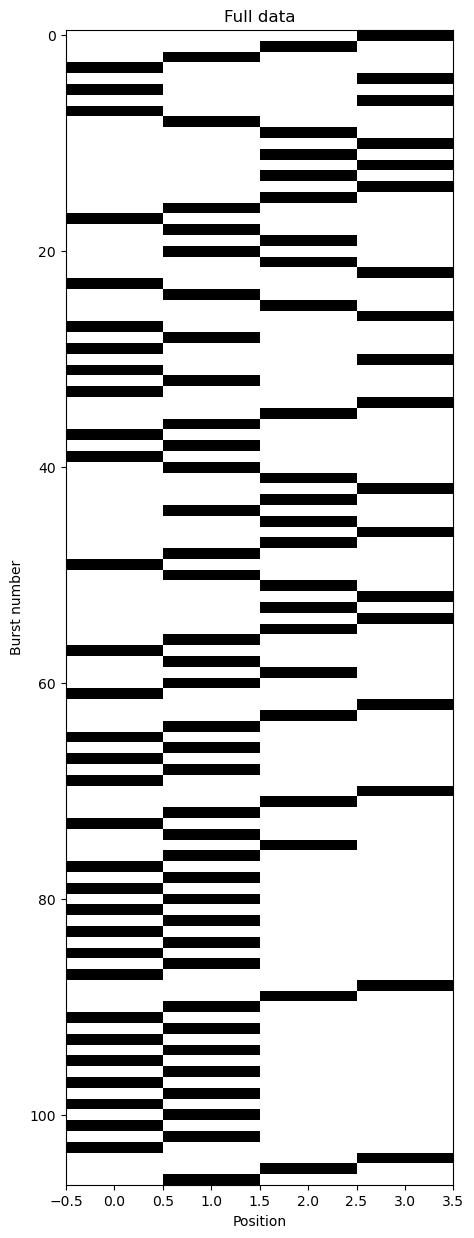

In [5]:
xtplot = np.zeros((len(full_movement_df), 1 + max(full_movement_df["position"])))
for i in full_movement_df.index:
    xtplot[i, full_movement_df.loc[i, "position"]] = 1

plt.figure(figsize = (5, 15))
plt.imshow(xtplot, aspect = "auto", interpolation = "none", cmap = "Greys")
plt.title("Full data")
plt.ylabel("Burst number")
plt.xlabel("Position")
plt.show()
#plt.close()

xtplot = np.zeros((len(pre_train_movement_df), 1 + max(pre_train_movement_df["position"])))
for i in pre_train_movement_df.index:
    xtplot[i, pre_train_movement_df.loc[i, "position"]] = 1

plt.figure(figsize = (5, 10))
plt.imshow(xtplot, aspect = "auto", interpolation = "none", cmap = "Greys")
plt.title("No stim")
plt.ylabel("Burst number")
plt.xlabel("Position")
#plt.show()
plt.close()


xtplot = np.zeros((len(train_movement_df), 1 + max(train_movement_df["position"])))
for i in train_movement_df.index:
    xtplot[i, train_movement_df.loc[i, "position"]] = 1

plt.figure(figsize = (5, 10))
plt.imshow(xtplot, aspect = "auto", interpolation = "none", cmap = "Greys")
plt.title("Stim")
plt.ylabel("Burst number")
plt.xlabel("Position")
#plt.show()
plt.close()


In [6]:

midway = (min(train_movement_df["frameno"]) + max(train_movement_df["frameno"]))/2

first_half_train_movement_df = train_movement_df.loc[train_movement_df["frameno"] < midway, :].reset_index()
second_half_train_movement_df = train_movement_df.loc[train_movement_df["frameno"] > midway, :].reset_index()

midway = (min(pre_train_movement_df["frameno"]) + max(pre_train_movement_df["frameno"]))/2

first_half_pre_train_movement_df = pre_train_movement_df.loc[pre_train_movement_df["frameno"] < midway, :].reset_index()
second_half_pre_train_movement_df = pre_train_movement_df.loc[pre_train_movement_df["frameno"] > midway, :].reset_index()

In [7]:
train_transition_df = m1da.build_transition_df(train_movement_df, world)
pre_train_transition_df = m1da.build_transition_df(pre_train_movement_df, world)
first_half_train_transition_df = m1da.build_transition_df(first_half_train_movement_df, world)
second_half_train_transition_df = m1da.build_transition_df(second_half_train_movement_df, world)

first_half_pre_train_transition_df = m1da.build_transition_df(first_half_pre_train_movement_df, world)
second_half_pre_train_transition_df = m1da.build_transition_df(second_half_pre_train_movement_df, world)

train_transition_df

,leftward,rightward,total,proportion left,object
0,4.0,15.0,19.0,0.210526,1
1,19.0,2.0,21.0,0.904762,0
2,7.0,0.0,7.0,1.000000,0
3,4.0,0.0,4.0,1.000000,0


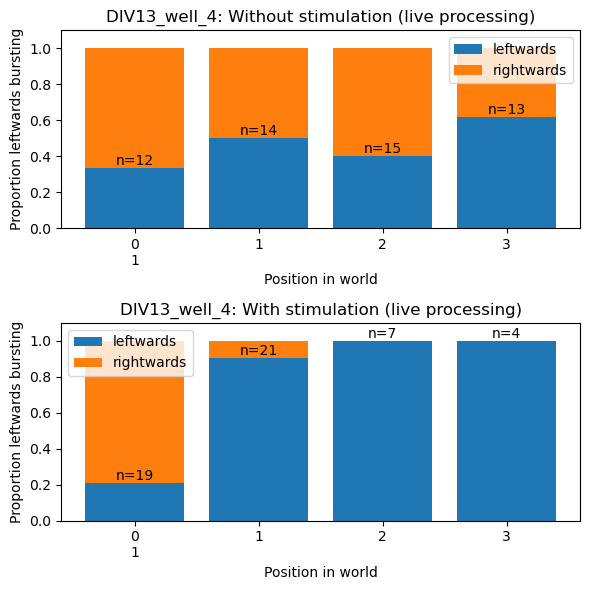

In [8]:
plt.figure(figsize = (6, 6))
ax = plt.subplot(212)
plt.title(filename + ": With stimulation (live processing)")
m1da.make_probability_bars(train_transition_df, world)

ax = plt.subplot(211)
plt.title(filename + ": Without stimulation (live processing)")
m1da.make_probability_bars(pre_train_transition_df, world)

plt.tight_layout()

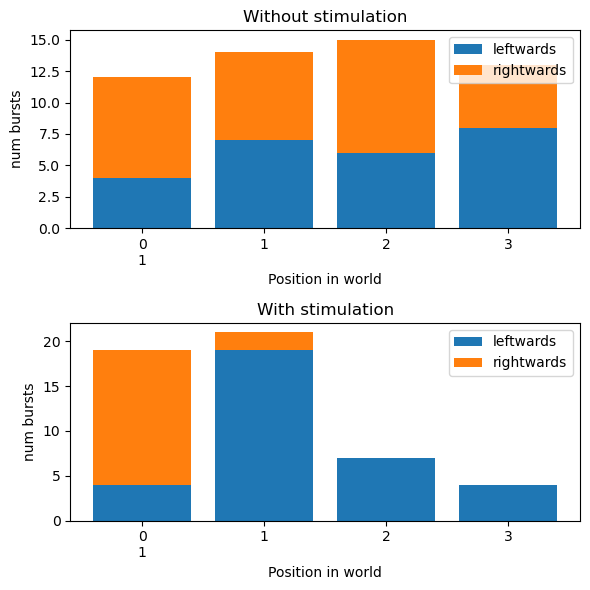

In [9]:
plt.figure(figsize = (6, 6))
ax = plt.subplot(212)
plt.title("With stimulation")
m1da.make_count_bars(train_transition_df, world)

ax = plt.subplot(211)
plt.title("Without stimulation")
m1da.make_count_bars(pre_train_transition_df, world)

plt.tight_layout()
plt.show()

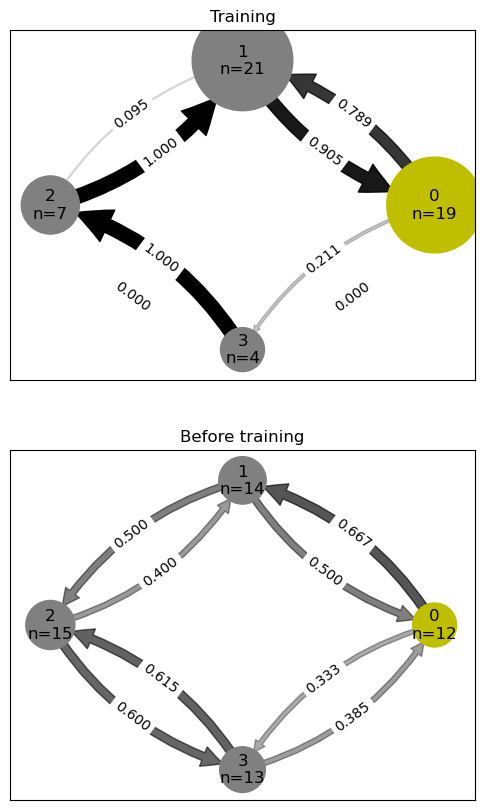

In [10]:
plt.figure(figsize = (6, 10))
plt.subplot(211)
plt.title("Training")
m1da.make_network_graph(train_transition_df, world)
plt.subplot(212)
plt.title("Before training")
m1da.make_network_graph(pre_train_transition_df, world)

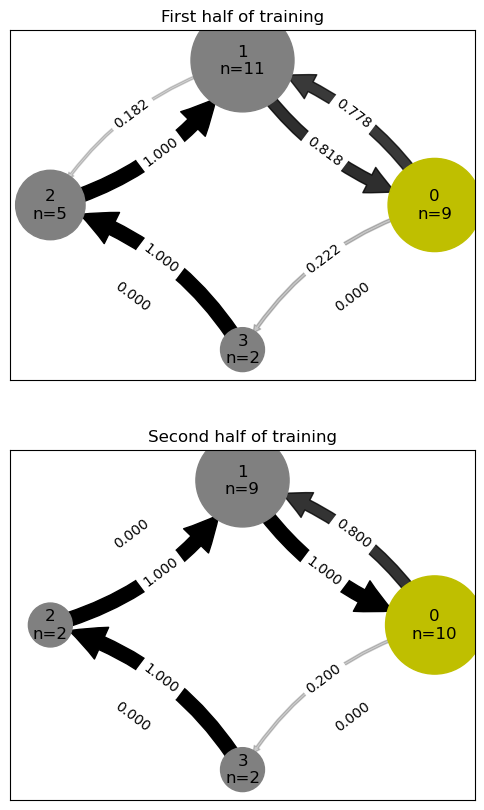

In [11]:
plt.figure(figsize = (6, 10))
plt.subplot(211)
plt.title("First half of training")
m1da.make_network_graph(first_half_train_transition_df, world)
plt.subplot(212)
plt.title("Second half of training")
m1da.make_network_graph(second_half_train_transition_df, world)

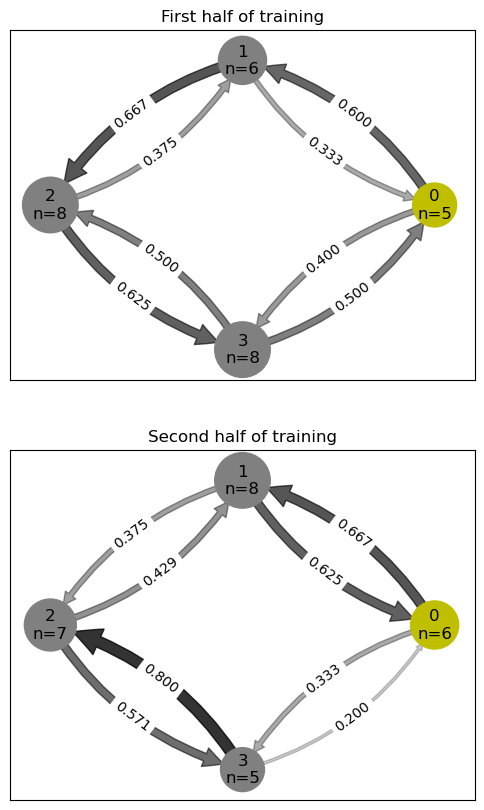

In [12]:
plt.figure(figsize = (6, 10))
plt.subplot(211)
plt.title("First half of training")
m1da.make_network_graph(first_half_pre_train_transition_df, world)
plt.subplot(212)
plt.title("Second half of training")
m1da.make_network_graph(second_half_pre_train_transition_df, world)

# Process the real data and get burst direction probabilities

In [13]:
display( train_movement_df)
display(pre_train_movement_df)
display(full_movement_df)

,frameno,time,position
0,18454152,1845.4152,2
1,18783366,1878.3366,1
2,19070091,1907.0091,0
3,19359419,1935.9419,1
4,19656621,1965.6621,2
5,19954108,1995.4108,1
6,20272760,2027.276,0
7,20710597,2071.0597,3
8,20997244,2099.7244,2
9,21294688,2129.4688,1


,frameno,time,position
0,50533,5.0533,3
1,210065,21.0065,2
2,525240,52.524,1
3,846041,84.6041,0
4,1179294,117.9294,3
5,1698281,169.8281,0
6,1966411,196.6411,3
7,2177485,217.7485,0
8,2470514,247.0514,1
9,2758342,275.8342,2


,frameno,time,position
0,50533,5.0533,3
1,210065,21.0065,2
2,525240,52.524,1
3,846041,84.6041,0
4,1179294,117.9294,3
...,...,...,...
102,34556547,3455.6547,1
103,35130059,3513.0059,0
104,35408757,3540.8757,3
105,35716694,3571.6694,2


['events', 'groups', 'recording_id', 'settings', 'spikes', 'start_time', 'stop_time', 'well_id']


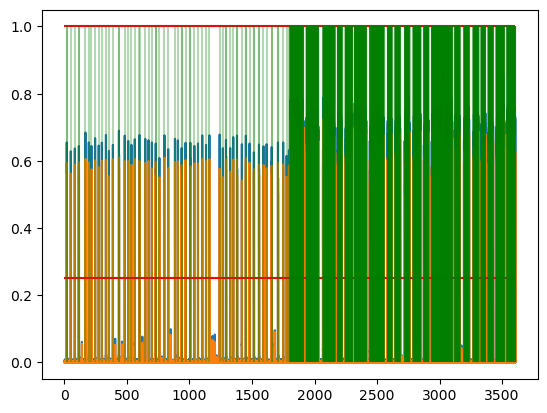

burst found in bin 1864 (time 18.44 s)
burst found in bin 1962 (time 19.42 s)
burst found in bin 5098 (time 50.78 s)
burst found in bin 8325 (time 83.05 s)
burst found in bin 11547 (time 115.27 s)
burst found in bin 11653 (time 116.33 s)
burst found in bin 16836 (time 168.16 s)
burst found in bin 19516 (time 194.96 s)
burst found in bin 21623 (time 216.03 s)
burst found in bin 24566 (time 245.46 s)
burst found in bin 27428 (time 274.08 s)
burst found in bin 29958 (time 299.38 s)
burst found in bin 33207 (time 331.87 s)
burst found in bin 35584 (time 355.64 s)
burst found in bin 38772 (time 387.52 s)
burst found in bin 43601 (time 435.81 s)
burst found in bin 43715 (time 436.95 s)
burst found in bin 48235 (time 482.15 s)
burst found in bin 51045 (time 510.25 s)
burst found in bin 53616 (time 535.96 s)
burst found in bin 56260 (time 562.40 s)
burst found in bin 59973 (time 599.53 s)
burst found in bin 60078 (time 600.58 s)
burst found in bin 64686 (time 646.66 s)
burst found in bin 67263

In [14]:
burst_list = m1da.find_bursts(filepath, filename, well_no, recording_no, burst_thresh = 3, datapath = datapath, stim_thresh = 1) # don't filter out stimulations by burst size - do it with events.
print(len(burst_list))

In [15]:
p = re.compile(r"stimulation\":\"\L<world_locs>\"", world_locs=set(world))

#this intermediate step isn't actually necessary
stimulation_events = events.loc[["stimulation" in i for i in events["eventmessage_decoded"]], :]
# for i in stimulation_events["eventmessage_decoded"]:
#     print(i)


big_stimulation_events = stimulation_events.loc[[not (p.search(i) is None) for i in stimulation_events["eventmessage_decoded"]], :]
big_stimulation_events.head()

,frameno,eventtype,eventid,eventmessage,frameno_adjusted,time,eventmessage_decoded
444,218730601,1,178,"b'{""amp_mV"":""200"",""dac"":""2"",""num_trains"":""5"",""...",19070141,1907.0141,"{""amp_mV"":""200"",""dac"":""2"",""num_trains"":""5"",""ph..."
445,218786179,1,179,"b'{""amp_mV"":""200"",""dac"":""2"",""end_stimulation"":...",19125719,1912.5719,"{""amp_mV"":""200"",""dac"":""2"",""end_stimulation"":""1..."
860,219933270,1,178,"b'{""amp_mV"":""200"",""dac"":""2"",""num_trains"":""5"",""...",20272810,2027.2810,"{""amp_mV"":""200"",""dac"":""2"",""num_trains"":""5"",""ph..."
861,219988848,1,179,"b'{""amp_mV"":""200"",""dac"":""2"",""end_stimulation"":...",20328388,2032.8388,"{""amp_mV"":""200"",""dac"":""2"",""end_stimulation"":""1..."
1302,221241847,1,178,"b'{""amp_mV"":""200"",""dac"":""2"",""num_trains"":""5"",""...",21581387,2158.1387,"{""amp_mV"":""200"",""dac"":""2"",""num_trains"":""5"",""ph..."


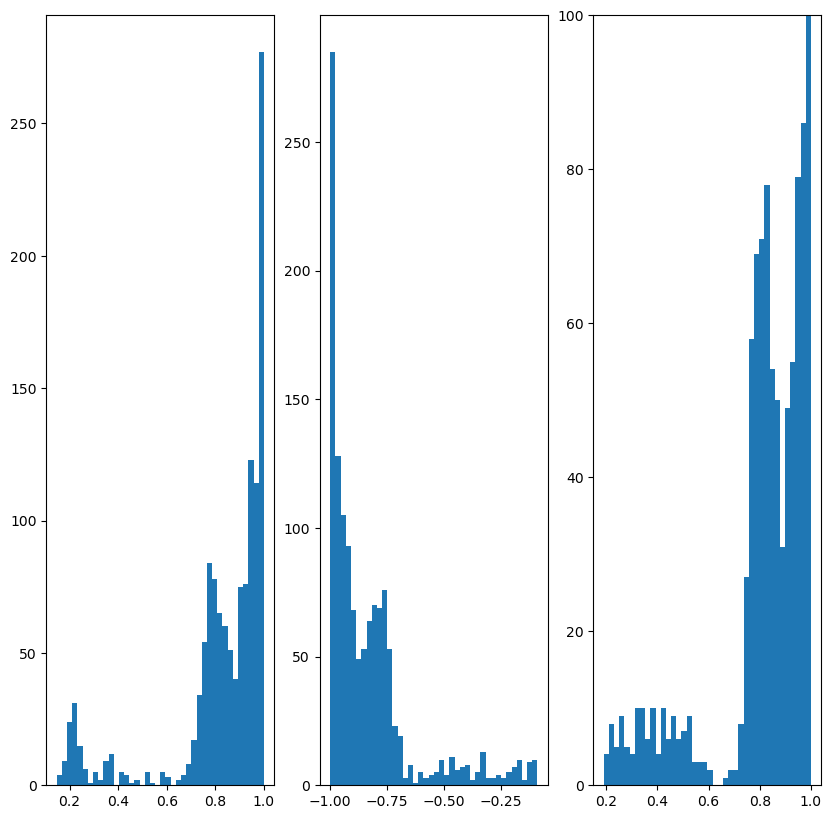

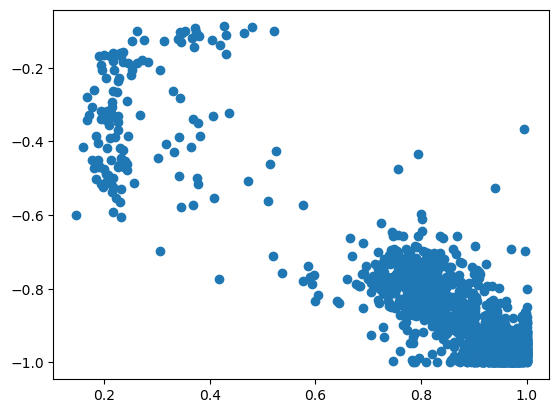

In [16]:
onset_list = list()
offset_list = list()
maxes = list()
for i in burst_list:
    onset_frac = i.calculate_onset_offset(1)[1]/i.max_height()
    offset_frac = i.calculate_onset_offset(1)[0]/i.max_height()
    max_val = max(onset_frac, -offset_frac)
    #if 0.61 > max_val > 0.5:
    #   i.plot()
    #   print(i.calculate_onset_offset())
    #   print(onset_frac)
    #   print(offset_frac)
    onset_list.append(onset_frac)
    offset_list.append(offset_frac)
    maxes.append(max(onset_frac, -offset_frac))

plt.figure(figsize = (10, 10))
plt.subplot(131)
plt.hist(onset_list, 40)
plt.subplot(132)
plt.hist(offset_list, 40)
plt.subplot(133)
plt.hist(maxes, 40)
plt.ylim(0, 100)
plt.show()
#plt.plot(offset_list)
#plt.plot()
plt.figure()
plt.scatter(onset_list, offset_list)

In [17]:
trimmed_burst_list = list()
thresh = 0.61

#First remove the stims that we know we don't care about.
for i, burst in enumerate(burst_list):
    time = burst.time
    sub_big_stimulation_events = big_stimulation_events.loc[big_stimulation_events["time"] < time + 0.5].reset_index(drop = True)
    if len(sub_big_stimulation_events) > 0 and "start_stimulation" in sub_big_stimulation_events.loc[len(sub_big_stimulation_events) - 1, "eventmessage_decoded"]:
        #print(sub_big_stimulation_events.loc[len(sub_big_stimulation_events) - 1, :])
        print("removing burst at time " + str(time))
    else:
        trimmed_burst_list.append(burst)

print("Secondary burst removal:")
second_trimmed_burst_list= list()
for i, burst in enumerate(trimmed_burst_list):
    onset_frac = burst.calculate_onset_offset()[1]/burst.max_height()
    offset_frac = burst.calculate_onset_offset()[0]/burst.max_height()
    max_val = max(onset_frac, -offset_frac)
    time = burst.time
    if max_val > thresh:
        print("removing burst at time " + str(time))

    else:
        second_trimmed_burst_list.append(burst)

print(len(second_trimmed_burst_list))

print("Tertiary burst removal:")
for i in range(len(second_trimmed_burst_list) - 1, 1, -1):
    if second_trimmed_burst_list[i].time - 1 < second_trimmed_burst_list[i-1].time:
        second_trimmed_burst_list.pop(i)

print(len(second_trimmed_burst_list))

removing burst at time 1906.6300000000017
removing burst at time 1907.7900000000016
removing burst at time 1908.9000000000017
removing burst at time 1909.9900000000016
removing burst at time 1911.0800000000017
removing burst at time 2026.9100000000017
removing burst at time 2028.0200000000018
removing burst at time 2029.1200000000017
removing burst at time 2030.2900000000018
removing burst at time 2031.3700000000017
removing burst at time 2157.7900000000022
removing burst at time 2158.870000000002
removing burst at time 2159.990000000002
removing burst at time 2161.090000000002
removing burst at time 2162.2500000000023
removing burst at time 2214.360000000002
removing burst at time 2215.470000000002
removing burst at time 2216.550000000002
removing burst at time 2217.6500000000024
removing burst at time 2218.7700000000023
removing burst at time 2298.470000000002
removing burst at time 2299.620000000002
removing burst at time 2300.720000000002
removing burst at time 2301.8400000000024
r

In [18]:
print([i.time for i in second_trimmed_burst_list])
for i in list(second_trimmed_burst_list)[-20:0]:
    i.plot()
    print(i.burst_direction(0.1))

[18.440000000000015, 19.42000000000002, 50.780000000000044, 83.05000000000007, 115.2700000000001, 116.3300000000001, 168.16000000000017, 194.96000000000018, 216.0300000000002, 245.46000000000024, 274.08000000000027, 299.3800000000003, 331.8700000000003, 355.6400000000003, 387.5200000000004, 435.8100000000004, 436.9500000000004, 482.15000000000043, 510.25000000000045, 535.9600000000004, 562.4000000000004, 599.5300000000005, 600.5800000000005, 646.6600000000005, 672.4300000000005, 699.3500000000006, 730.0900000000006, 759.3800000000007, 799.9700000000007, 829.7900000000006, 883.9100000000008, 906.6900000000007, 937.0600000000007, 968.5000000000008, 1007.0300000000009, 1039.1400000000008, 1067.960000000001, 1102.140000000001, 1132.170000000001, 1159.260000000001, 1241.030000000001, 1266.660000000001, 1291.800000000001, 1292.900000000001, 1325.4900000000011, 1350.1100000000013, 1379.8300000000013, 1418.6800000000012, 1450.6400000000012, 1480.1800000000012, 1514.7500000000014, 1515.81000000

In [19]:
def get_position_when_burst(burst: Burst, movement_df: pd.DataFrame)-> int:
    time = burst.time

    position = -1
    

    for i in movement_df.index:
        previous_position = position

        transition_time = movement_df.loc[i, "time"]
        position = movement_df.loc[i, "position"]

        if time < transition_time:
            return previous_position
    

    return position
    

3
3
2
1
0
0
3
0
3
0
1
2
3
2
3
2
2
3
2
1
0
1
1
2
1
2
3
0
1
2
3
0
1
0
3
0
1
0
3
2
1
0
1
1
0
1
2
3
2
1
2
2
3
2
1
0
0
1
1
2
3
2
3
2
1
0
1
2
2
1
0
2
1
0
0
0
0
3
2
0
1
2
1
0
1
0
1
0
1
0
1
0
0
3
3
2
2
0
1
0
1
0
0
1
0
1
0
1
0
1
0
3
2


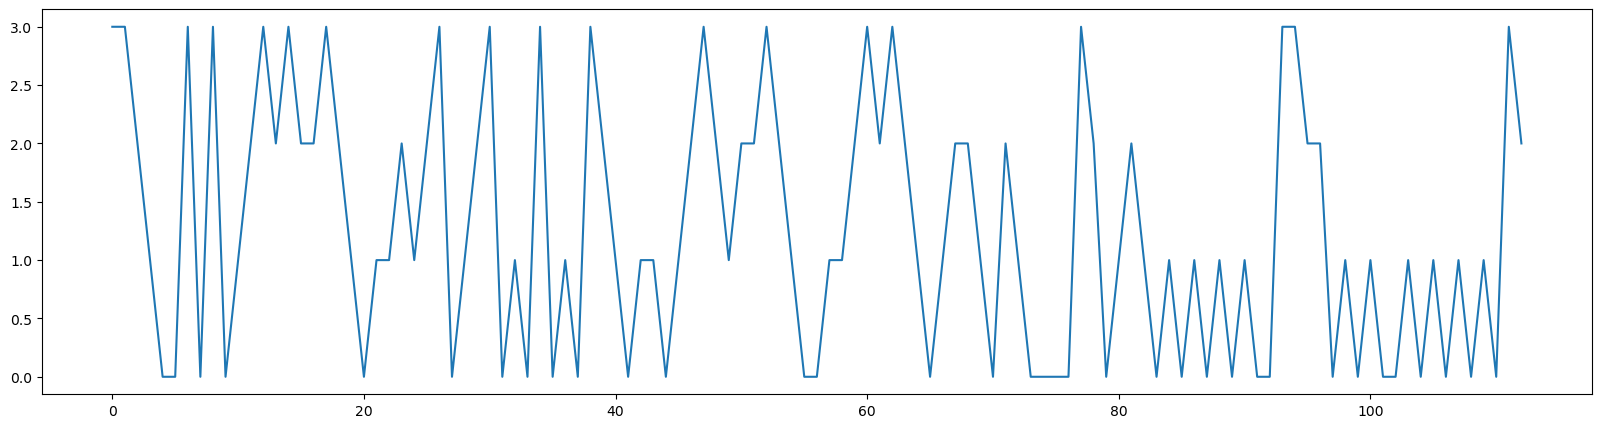

In [20]:
for burst in second_trimmed_burst_list:
    print(get_position_when_burst(burst, full_movement_df))

plt.figure(figsize = (20, 5))
plt.plot([get_position_when_burst(i, full_movement_df) for i in second_trimmed_burst_list])

,leftward,rightward,total,proportion left,object
0,0,0,NaN,NaN,1
1,0,0,NaN,NaN,0
2,0,0,NaN,NaN,0
3,0,0,NaN,NaN,0


,leftward,rightward,total,proportion left,object
0,0,0,NaN,NaN,1
1,0,0,NaN,NaN,0
2,0,0,NaN,NaN,0
3,0,0,NaN,NaN,0


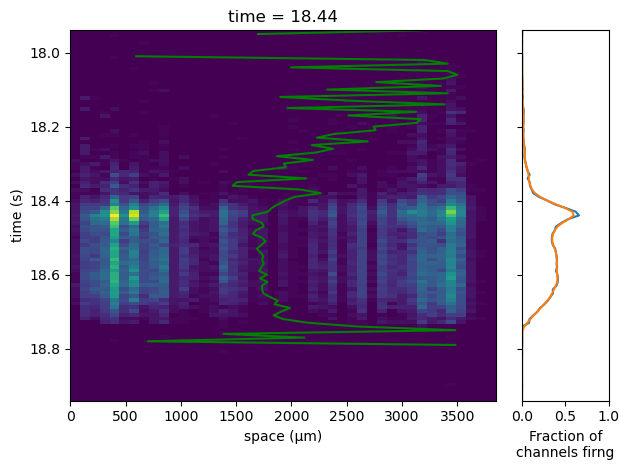

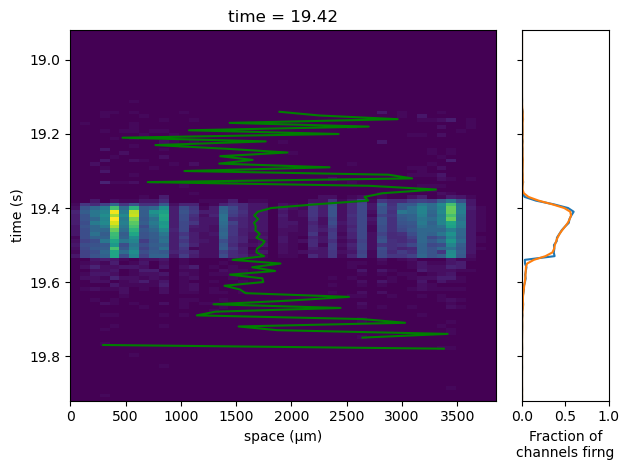

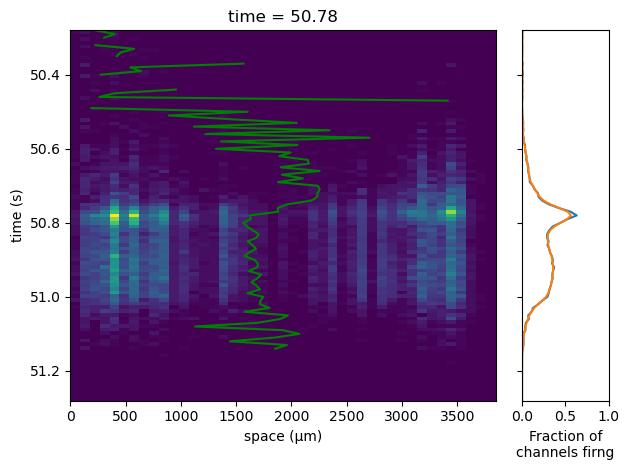

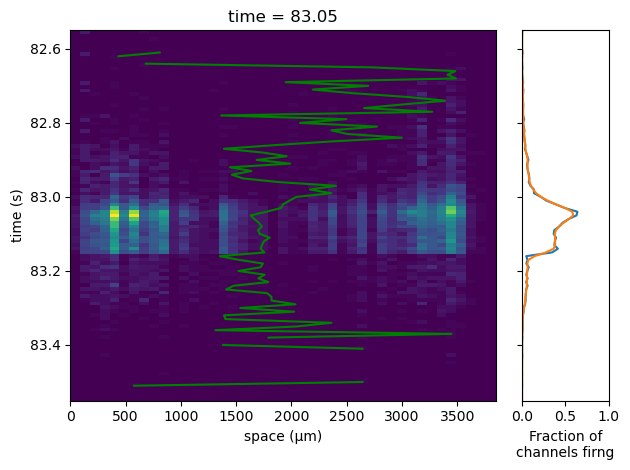

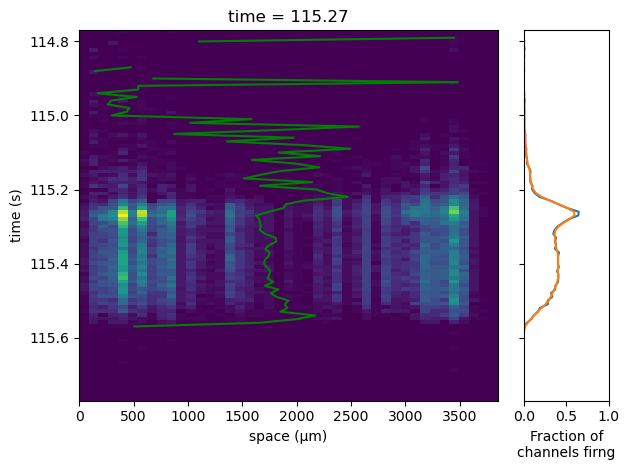

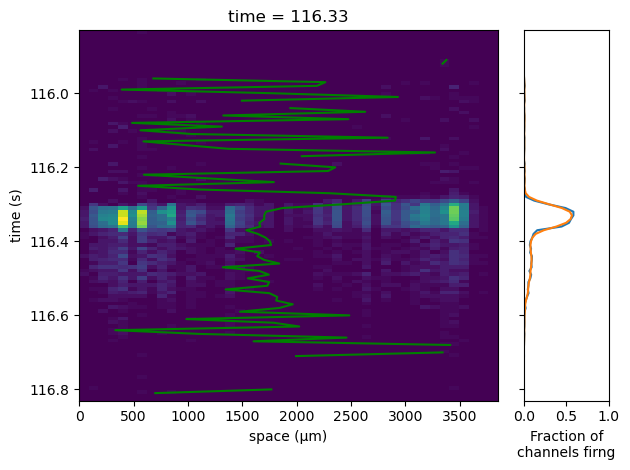

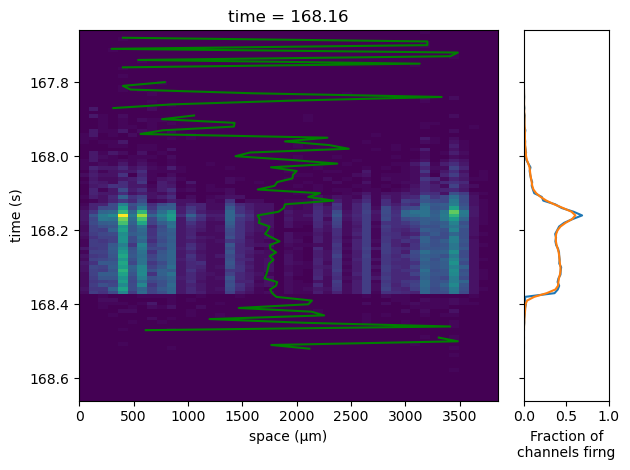

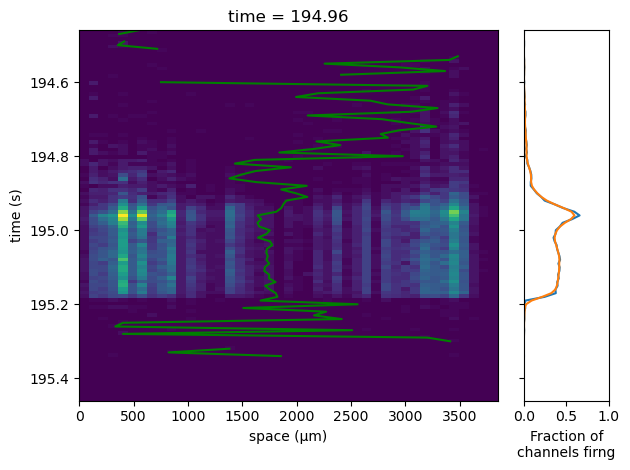

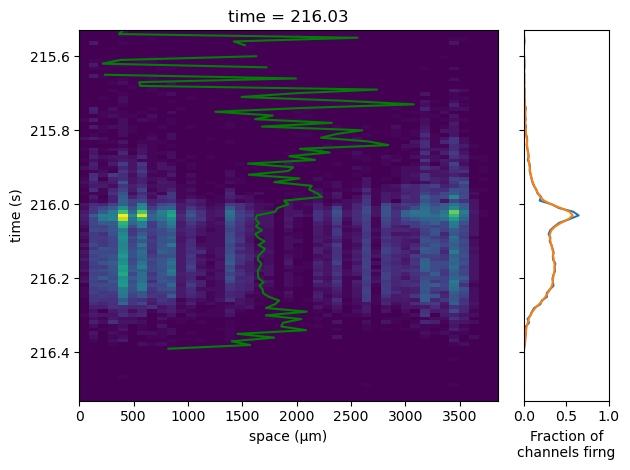

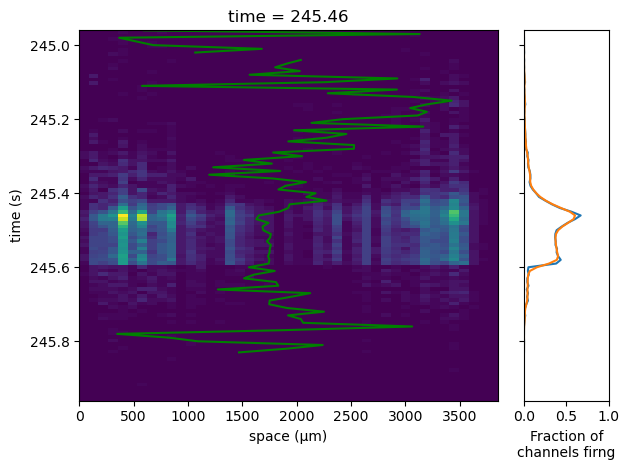

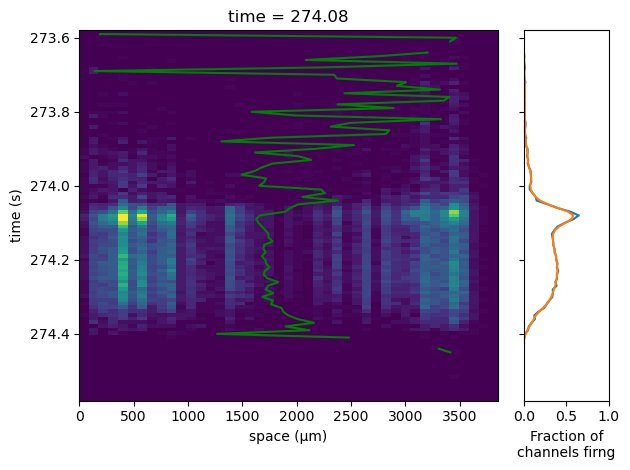

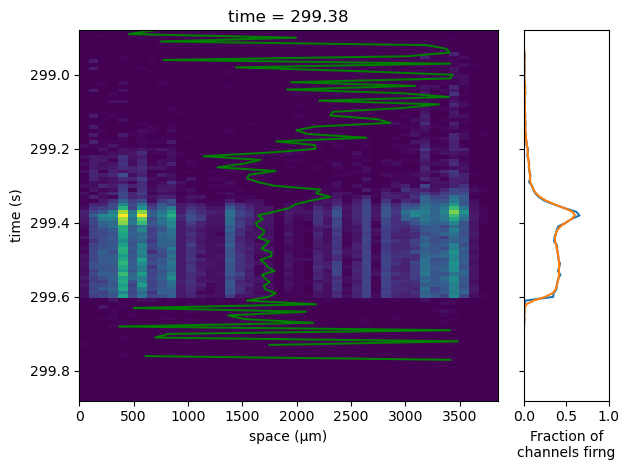

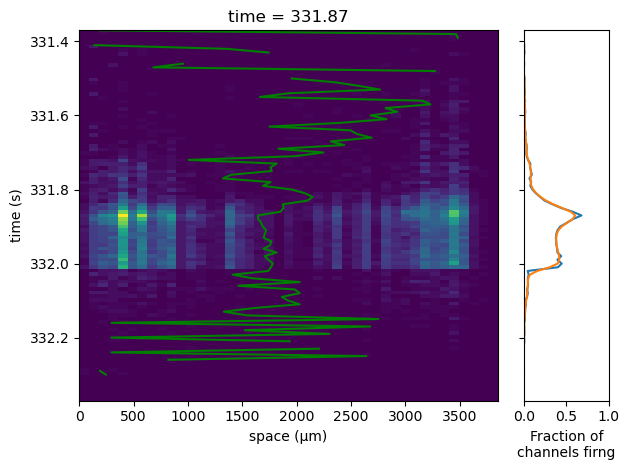

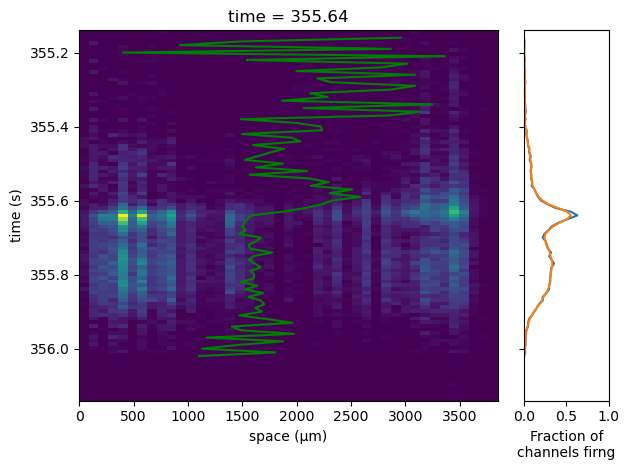

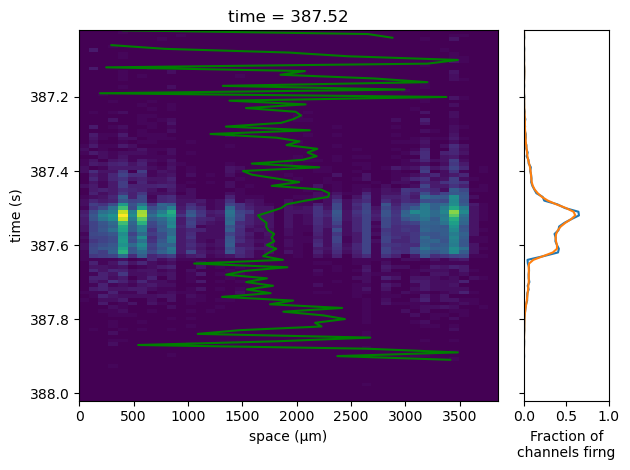

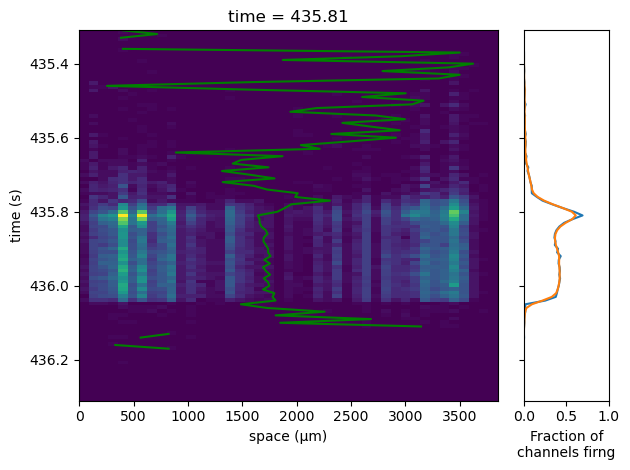

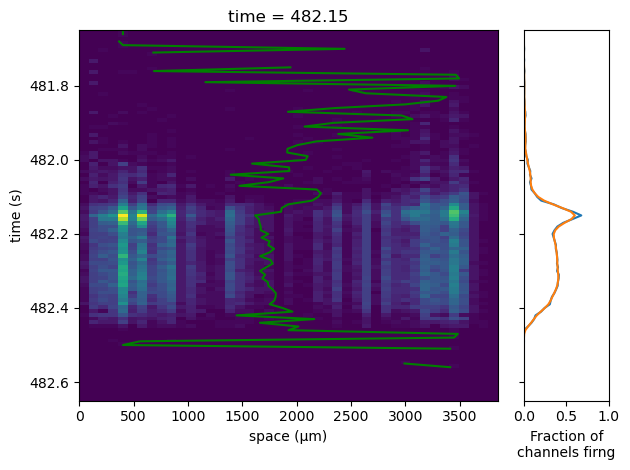

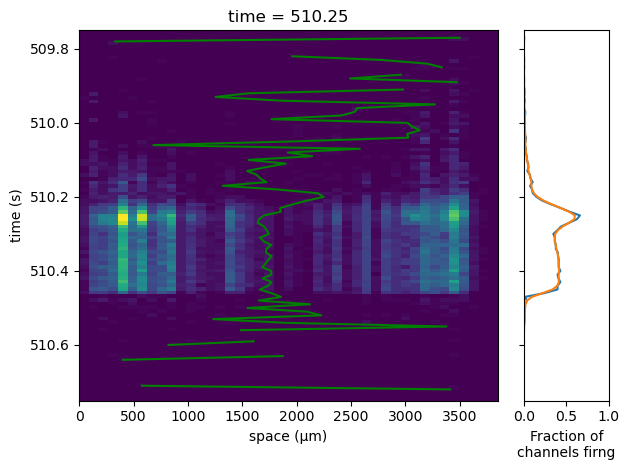

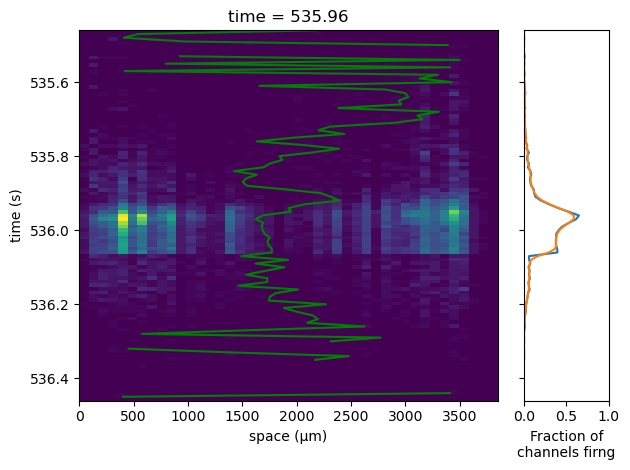

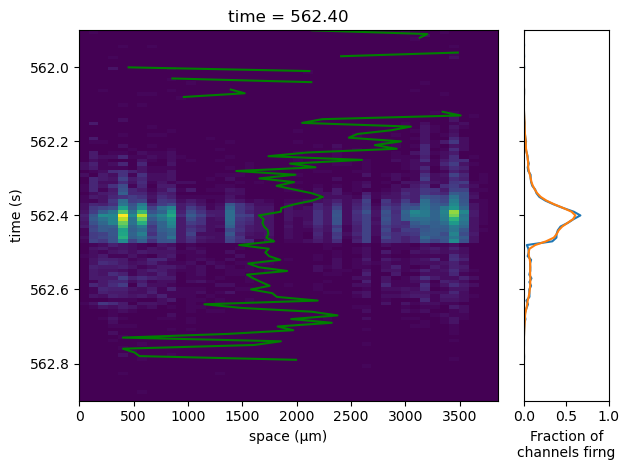

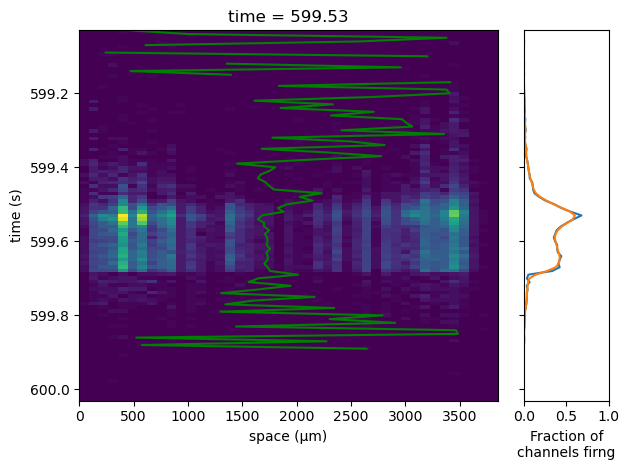

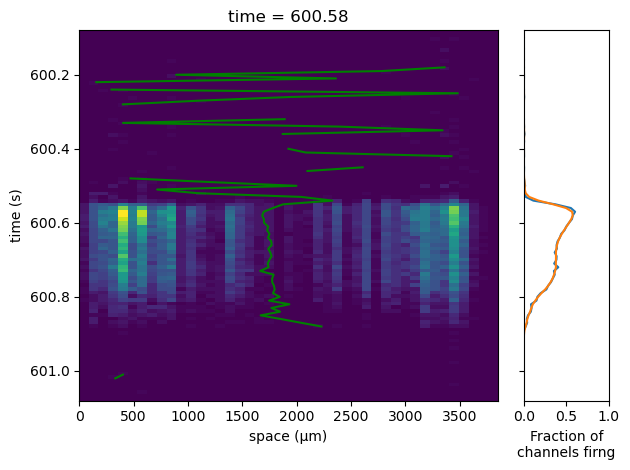

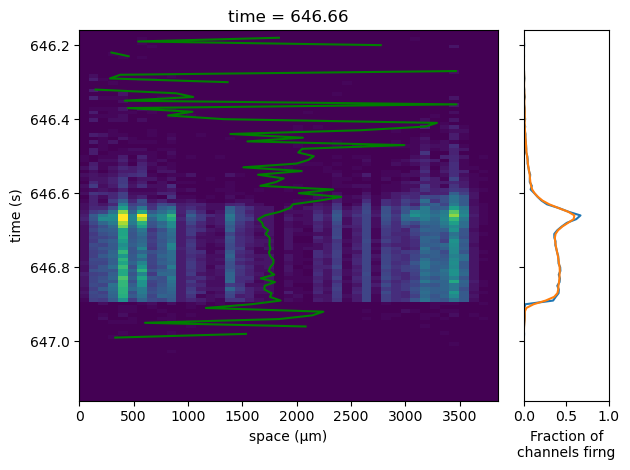

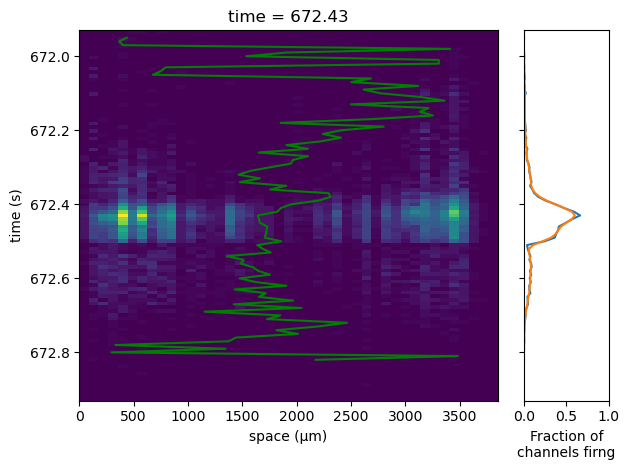

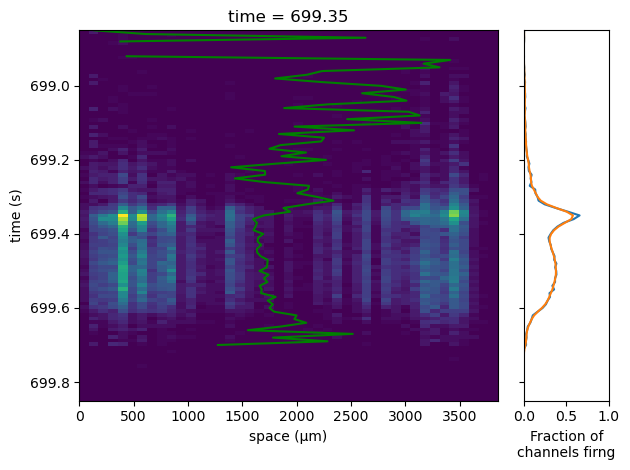

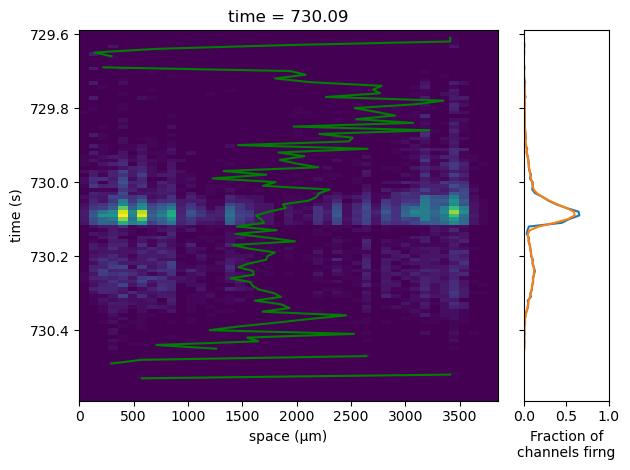

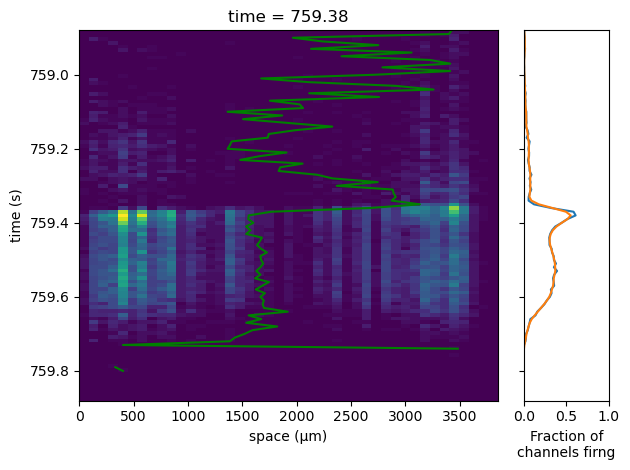

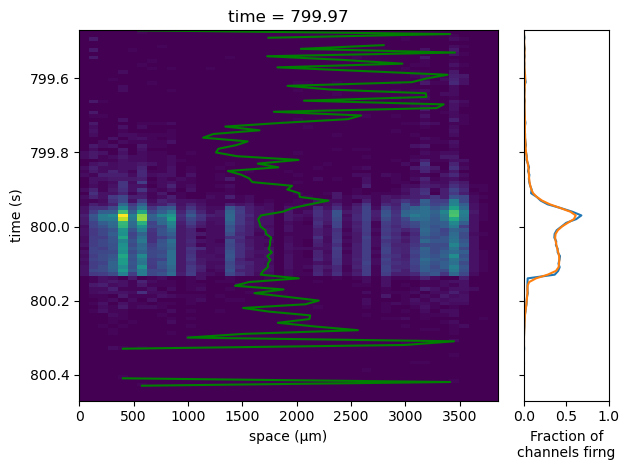

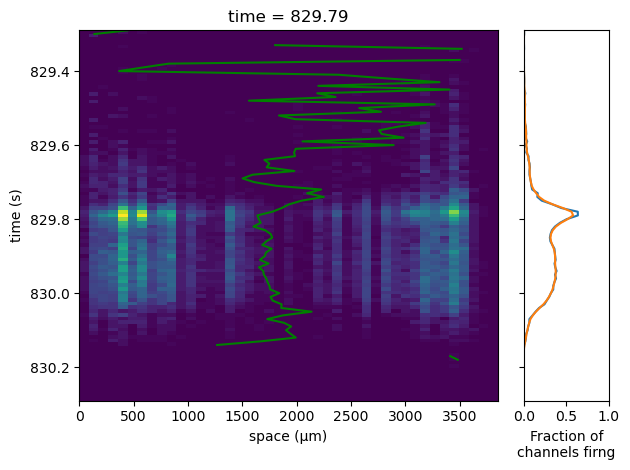

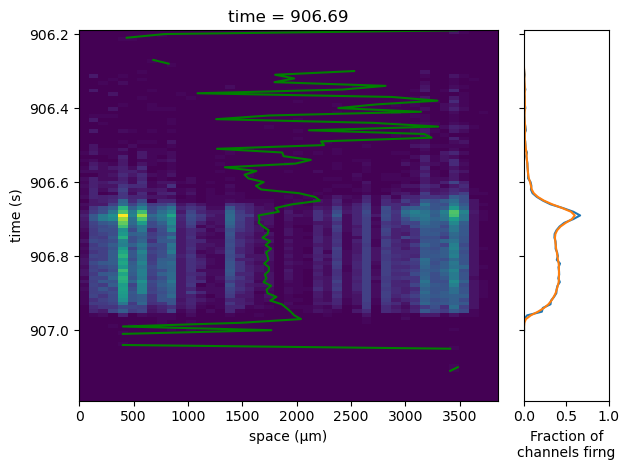

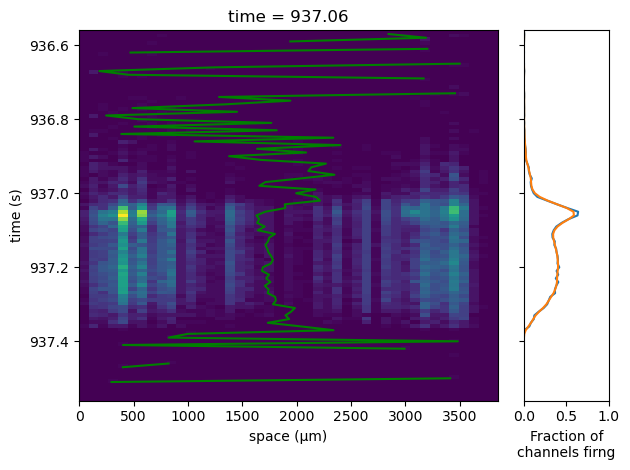

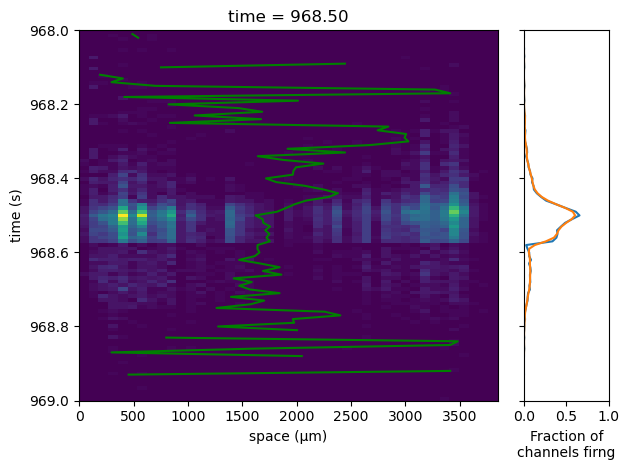

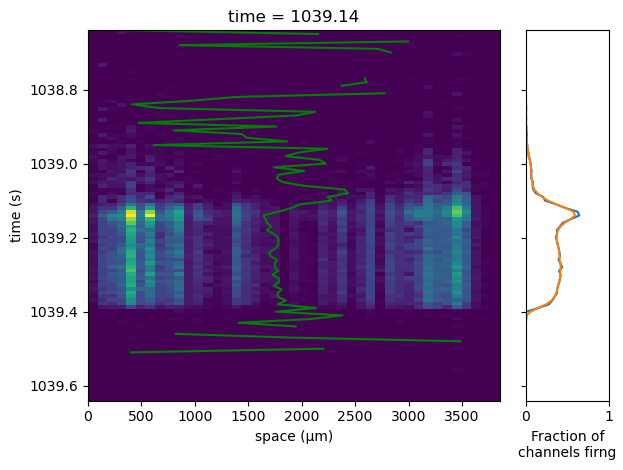

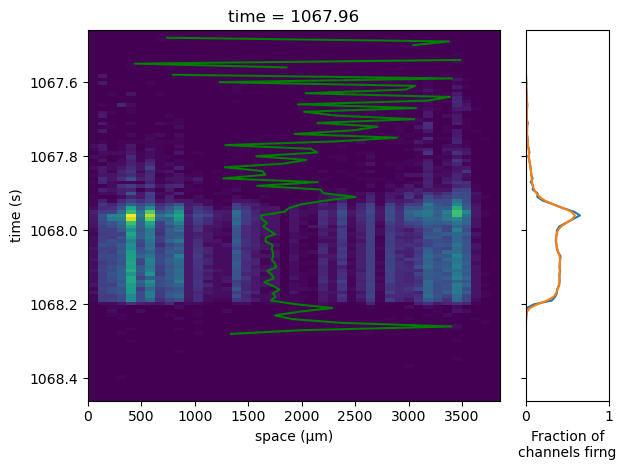

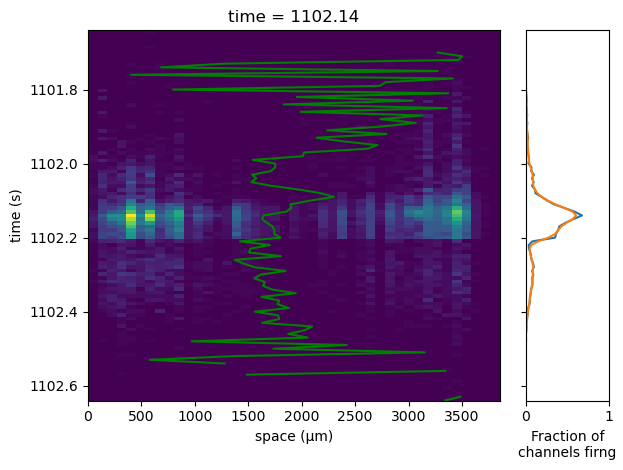

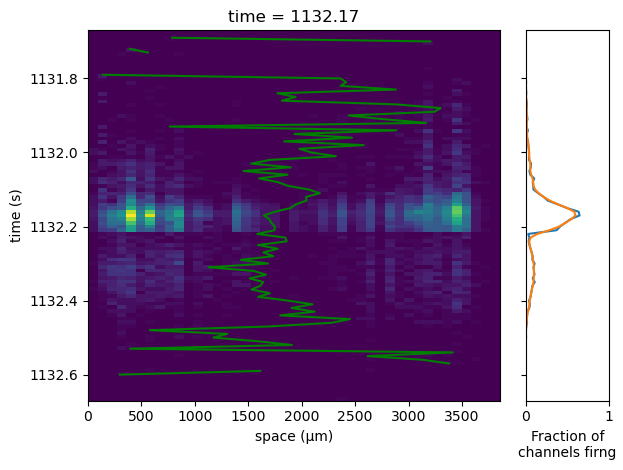

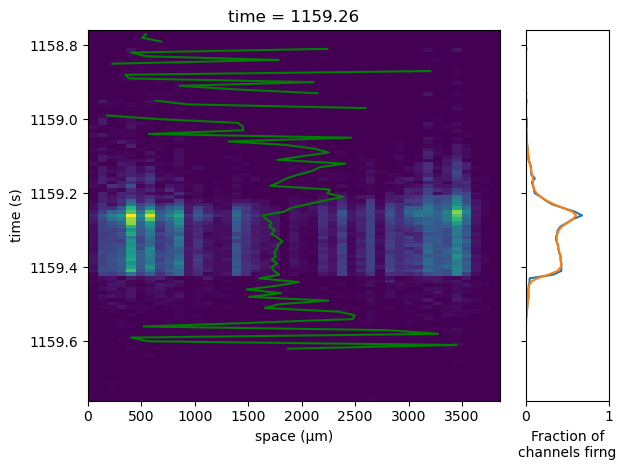

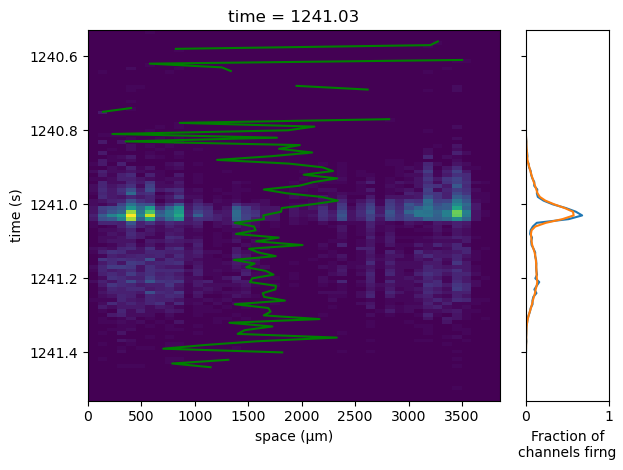

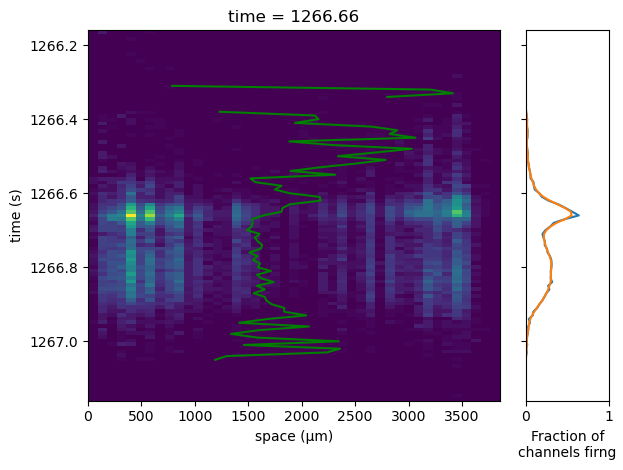

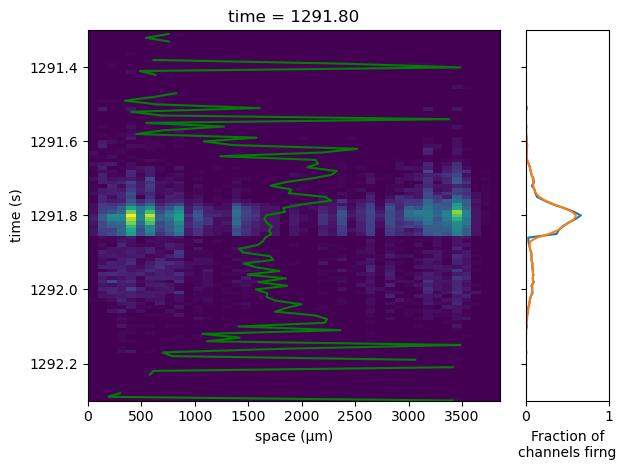

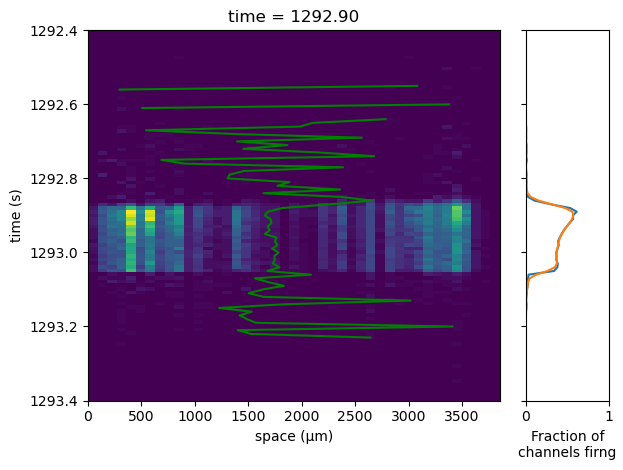

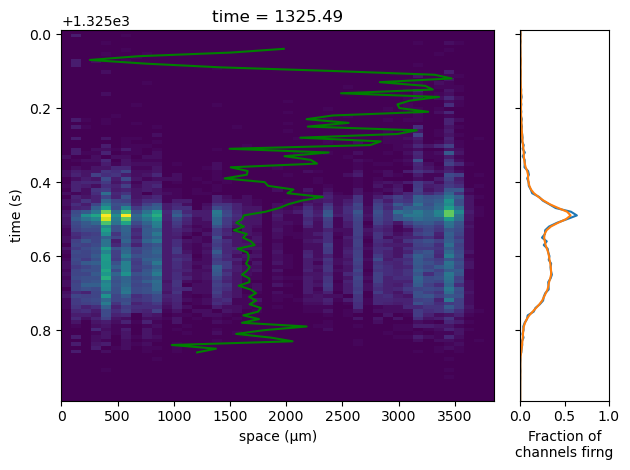

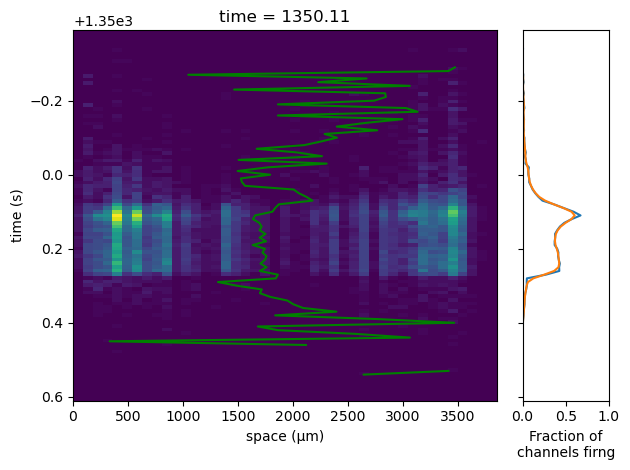

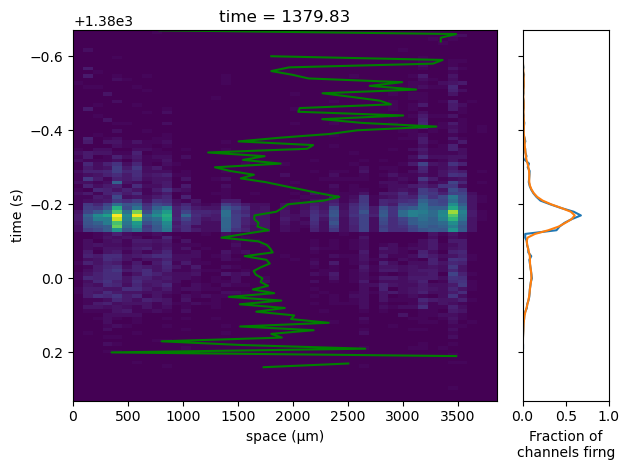

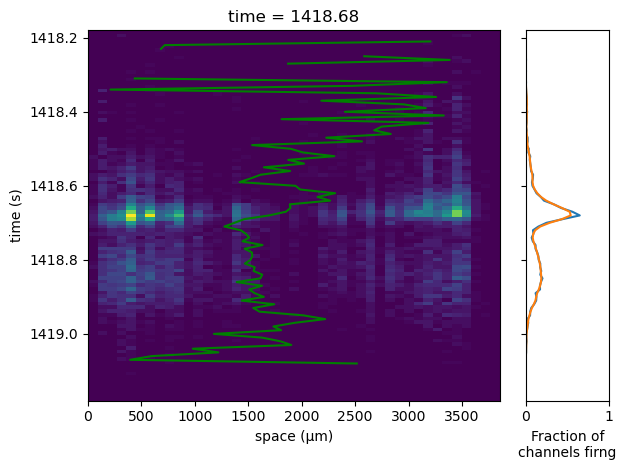

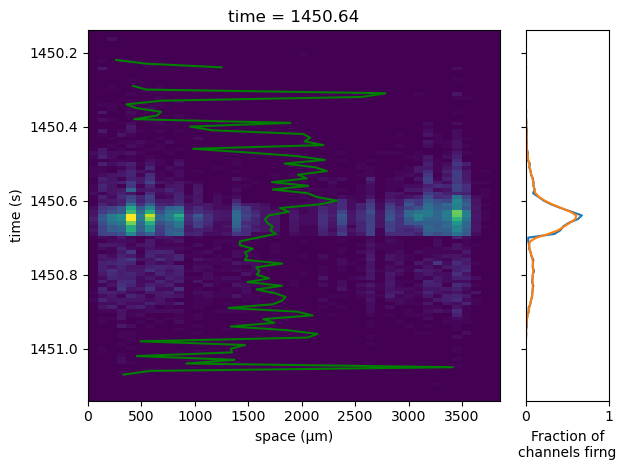

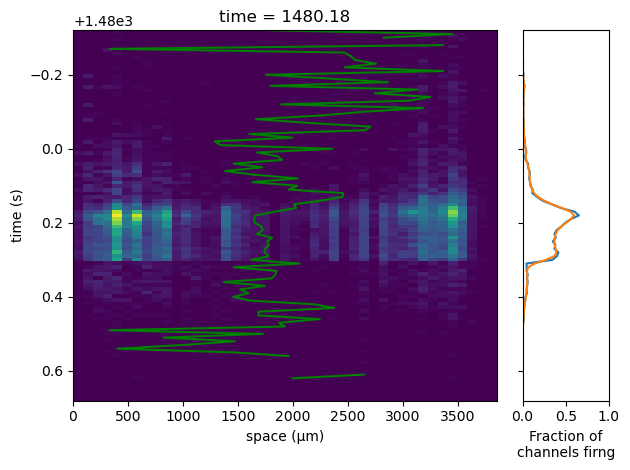

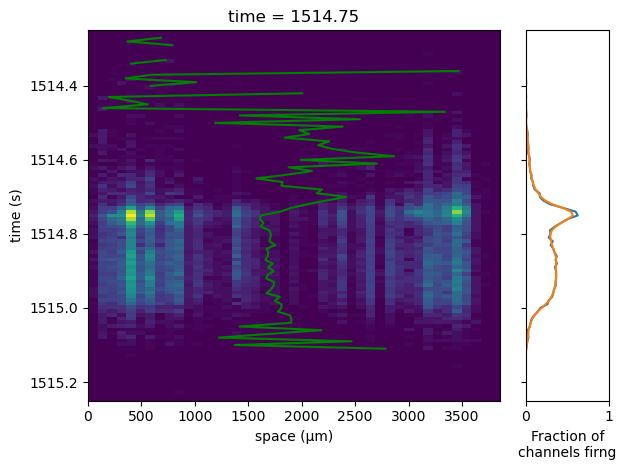

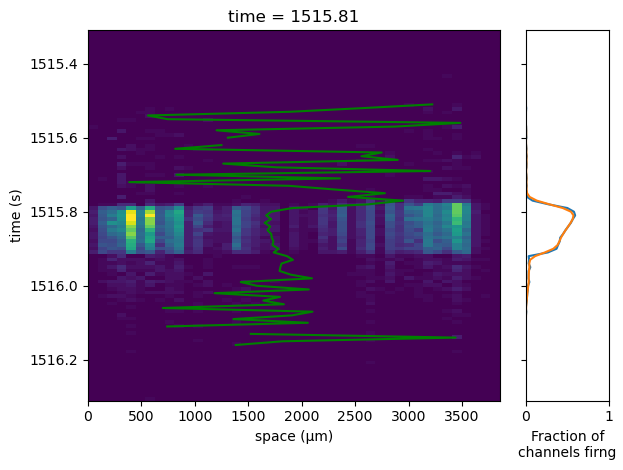

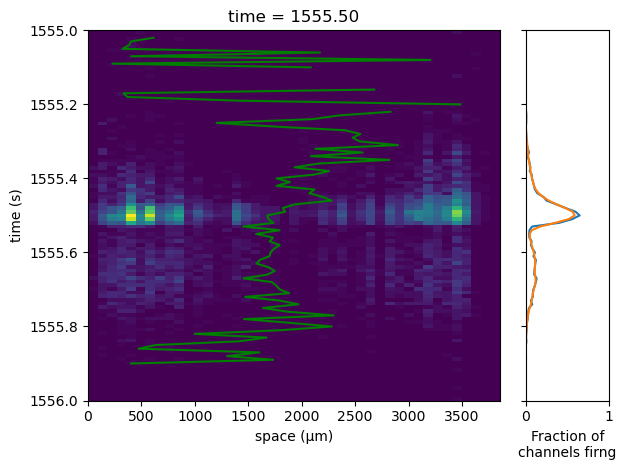

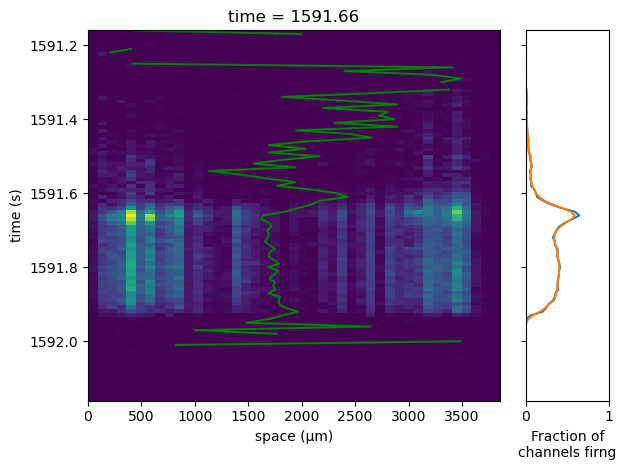

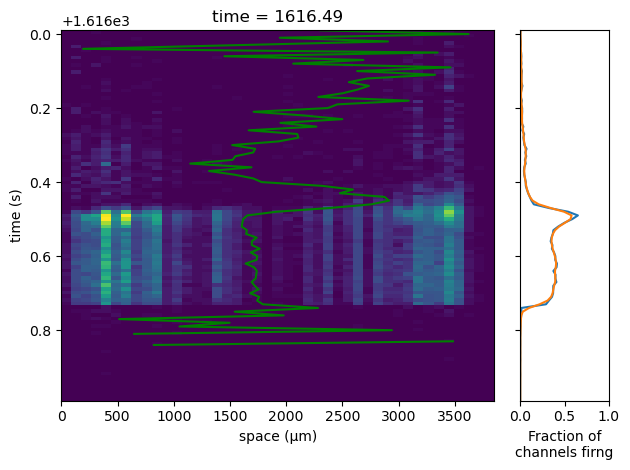

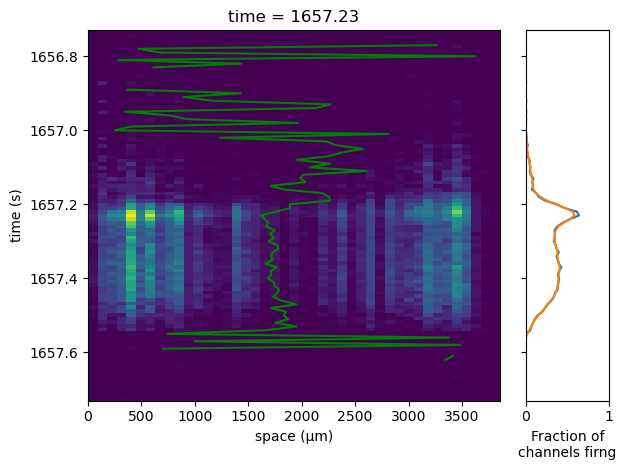

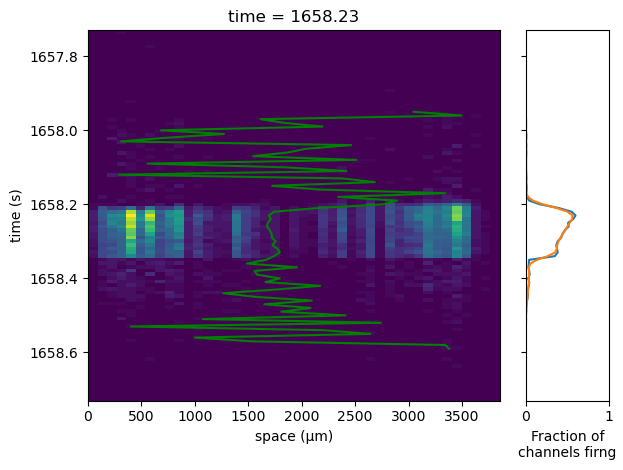

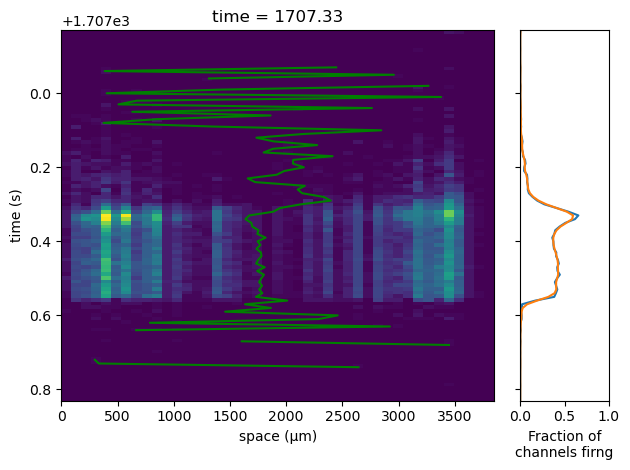

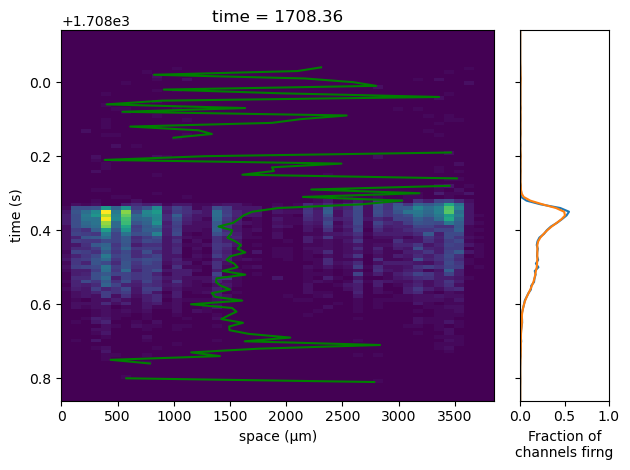

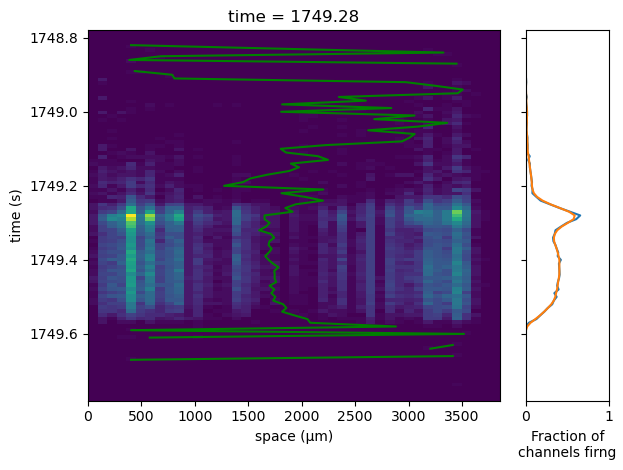

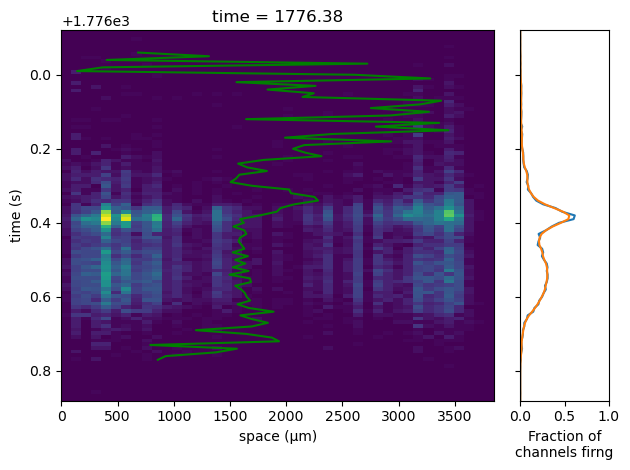

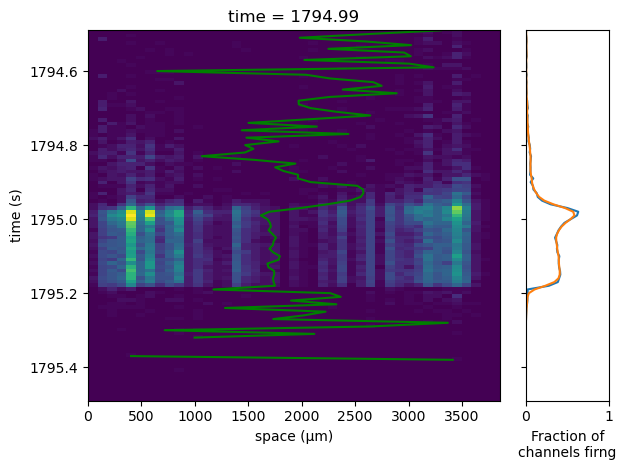

,leftward,rightward,total,proportion left,object
0,35,0,35,1.000000,1
1,33,0,33,1.000000,0
2,24,2,26,0.923077,0
3,17,2,19,0.894737,0


In [21]:
raw_data_transition_df = pd.DataFrame(columns = ["leftward", "rightward", "total", "proportion left", "object"], index = range(0, len(world)))
pre_train_raw_data_transition_df = pd.DataFrame(columns = ["leftward", "rightward", "total", "proportion left", "object"], index = range(0, len(world)))
train_raw_data_transition_df = pd.DataFrame(columns = ["leftward", "rightward", "total", "proportion left", "object"], index = range(0, len(world)))
raw_data_transition_df["leftward"] = 0
raw_data_transition_df["rightward"] = 0
train_raw_data_transition_df["leftward"] = 0
train_raw_data_transition_df["rightward"] = 0
pre_train_raw_data_transition_df["leftward"] = 0
pre_train_raw_data_transition_df["rightward"] = 0


raw_data_transition_df["object"] = list(world)
train_raw_data_transition_df["object"] = list(world)
pre_train_raw_data_transition_df["object"] = list(world)

display(train_raw_data_transition_df)
display(raw_data_transition_df)
for burst in second_trimmed_burst_list:
    burst_direction = burst.direction()
    position = get_position_when_burst(burst, full_movement_df)
    if burst_direction < 0:
        raw_data_transition_df.loc[position, "leftward"] += 1
        if burst.time < train_time:
            pre_train_raw_data_transition_df.loc[position, "leftward"] += 1
            burst.plot()
        else:
            train_raw_data_transition_df.loc[position, "leftward"] += 1
    else:
        raw_data_transition_df.loc[position, "rightward"] += 1
        if burst.time < train_time:
            pre_train_raw_data_transition_df.loc[position, "rightward"] += 1
        else:
            train_raw_data_transition_df.loc[position, "rightward"] += 1
    
raw_data_transition_df["total"] = raw_data_transition_df["leftward"] + raw_data_transition_df["rightward"] 
raw_data_transition_df["proportion left"] = raw_data_transition_df["leftward"]/raw_data_transition_df["total"]

train_raw_data_transition_df["total"] = train_raw_data_transition_df["leftward"] + train_raw_data_transition_df["rightward"] 
train_raw_data_transition_df["proportion left"] = train_raw_data_transition_df["leftward"]/train_raw_data_transition_df["total"]

pre_train_raw_data_transition_df["total"] = pre_train_raw_data_transition_df["leftward"] + pre_train_raw_data_transition_df["rightward"] 
pre_train_raw_data_transition_df["proportion left"] = pre_train_raw_data_transition_df["leftward"]/pre_train_raw_data_transition_df["total"]

raw_data_transition_df



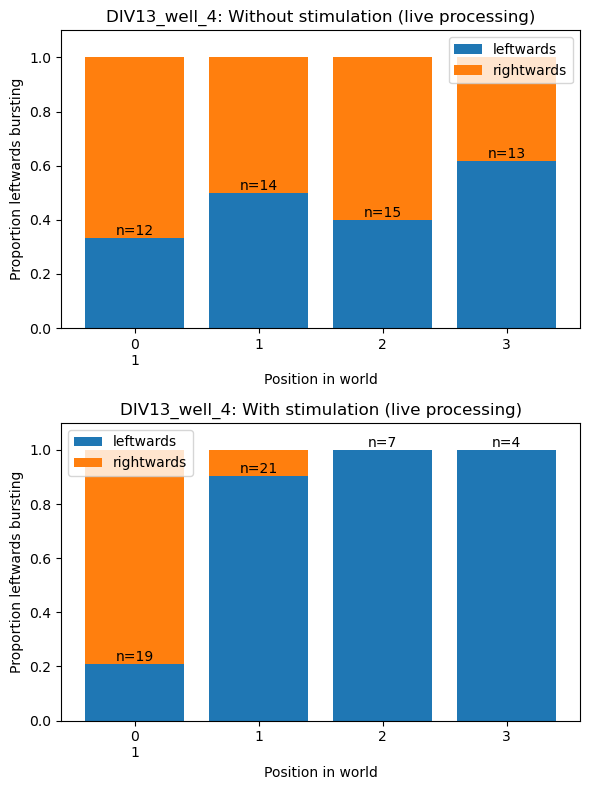

In [24]:
plt.figure(figsize = (6, 8))

ax = plt.subplot(212)
plt.title(filename + ": With stimulation (live processing)")
m1da.make_probability_bars(train_transition_df, world)

ax = plt.subplot(211)
plt.title(filename + ": Without stimulation (live processing)")
m1da.make_probability_bars(pre_train_transition_df, world)

plt.tight_layout()

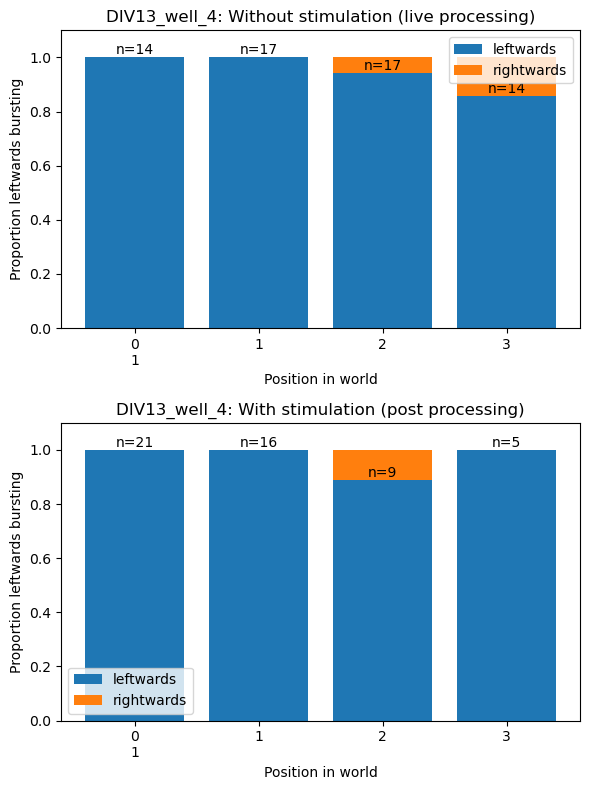

In [25]:
plt.figure(figsize = (6, 8))
plt.subplot(211)
plt.title(filename + ": Without stimulation (live processing)")
m1da.make_probability_bars(pre_train_raw_data_transition_df, world)

plt.subplot(212)
plt.title(filename + ": With stimulation (post processing)")
m1da.make_probability_bars(train_raw_data_transition_df, world)

plt.tight_layout()
